# Corpus atlas: consensus groups and the candidate pool (2026-10-24)

Revises the selection in [`zenodo_1053_tsne_261021`](zenodo_1053_tsne_261021.ipynb). There, Ward clusters partitioned every recording and were drawn on a fixed map. Here groups must earn their shading: they must be density cores in feature space, stable when parent recordings are resampled, span several parent recordings, and hold together as one region of the displayed map. The map is chosen *after* the groups are fixed, by how faithfully it shows them.

Protocol, fixed in `research/zenodo/atlas/configs/analysis/zenodo-consensus-261024.yaml` before any group was read for the narrative:
1. **Analysis space:** first 50 principal components of the primary z (section 1 gives the reason).
2. **Groups:** HDBSCAN (minimum cluster size 5, minimum samples 5) in that space; unassigned recordings stay unassigned.
3. **Pool:** cluster-wise Jaccard ≥ 0.75 under 50 subsets keeping 80% of parent recordings (Hennig 2007), and at least 3 parent recordings, so nested windows of one simulation cannot qualify.
4. **Map:** sweep input dimension × perplexity × exaggeration × 3 seeds. Score each map by the number of pool groups that fall ≥ 80% in one 2-D map region that is ≥ 50% theirs. Keep maps within 95% of the best 15-NN recall, and choose the highest score.
5. **Tiers:** tier 1 passes the pool and is one region on the chosen map; tier 2 passes the pool but splits; tier 3 is every other density group. Tiers 1–2 are the candidate pool. Illustrative choices are made from it afterwards, with the full list published.

Boundaries as before: co-location means a shared dependence-organisation signature, not a shared mechanism; tags are provenance, not truth; the map's gaps and island sizes are not interpreted. Code: `research/zenodo/atlas/consensus_atlas.py`. Outputs: `results/zenodo_7118947/consensus-261024/`.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import display
from threadpoolctl import threadpool_limits
from research.zenodo.atlas import consensus_atlas as ca
from research.zenodo.atlas import tsne_atlas as ta
%matplotlib inline

ta.notebook_style()
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 220)
config = yaml.safe_load(ca.CONFIG.read_text())
base = yaml.safe_load((ROOT / config["base"]).read_text())
OUT = ROOT / config["output"]
FIGURES = OUT / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
if not (OUT / "manifest.json").exists():
    with threadpool_limits(limits=config["threads"]):
        ca.compute(config, OUT)  # about 7 minutes on 8 cores
C = ca.load(OUT)
T = ta.load(ROOT / base["output"])
corpus = ta.load_corpus(base)
meta, A = corpus["meta"], T["arrays"]
density = C["arrays"]["density"]
groups = C["groups"].sort_values(["tier", "size"], ascending=[True, False]).reset_index(drop=True)
CHOSEN = C["manifest"]["chosen_map"]
xy = C["arrays"][f"map__{CHOSEN}"][0]
assert (meta.dataset.to_numpy() == C["arrays"]["names"]).all()
print(f"{len(groups)} density groups; {int((density >= 0).sum())} of {len(meta)} recordings assigned; "
      f"pool (tiers 1–2): {int((groups.tier <= 2).sum())}; tier 1: {int((groups.tier == 1).sum())}; chosen map: {CHOSEN}")

30 density groups; 452 of 1053 recordings assigned; pool (tiers 1–2): 10; tier 1: 9; chosen map: pca50-p50-x1


## 1. Analysis space: why the first 50 principal components

The full-rank z includes many low-variance directions. If they are mostly estimation noise, truncation should *raise* agreement between each recording's nearest neighbours and labels that played no part in fitting. The check below uses the source family, counting only neighbours from other parent recordings so that nested windows cannot inflate it. Agreement peaks at 50 components. The tail beyond that therefore behaves mostly like noise with respect to source structure, and truncation there is denoising rather than cosmetics. Two caveats: choosing one hyperparameter with labels is light supervision, and source is not ground truth for dependence character.

In [2]:
C["source_agreement"].round(3)

,input,dims,share
0,PCA5,5,0.450
1,PCA10,10,0.562
2,PCA20,20,0.615
3,PCA50,50,0.641
4,PCA100,100,0.628
5,PCA200,200,0.595
6,full rank,1052,0.544


## 2. Density groups and the pool

HDBSCAN finds dense cores and leaves the rest unassigned. Unlike a partition, it does not force the continuum into groups.

In [3]:
cols = ["group", "tier", "title", "size", "parents", "composition", "origin", "cross_source", "stability", "silhouette_full",
        "silhouette_pca", "size_survival", "p_matched", "in_modal_region", "M", "T", "source_mix"]
single = np.mean([len(set(meta.source[density == g])) == 1 for g in groups.group])
print(f"Assigned: {np.mean(density >= 0):.0%} of recordings. Single-source groups: {single:.0%}. "
      f"Stable (≥ 0.75): {int((groups.stability >= .75).sum())}; with ≥ 3 parents as well: {int(groups.pool.sum())}.")
groups[cols].round(2)

Assigned: 43% of recordings. Single-source groups: 60%. Stable (≥ 0.75): 13; with ≥ 3 parents as well: 10.


,group,tier,title,size,parents,composition,origin,cross_source,stability,silhouette_full,silhouette_pca,size_survival,p_matched,in_modal_region,M,T,source_mix
0,1,1,SelfRegulationSCP2 + SelfRegulationSCP1,39,39,heterogeneous,real,True,1.00,0.27,0.46,0.65,0.00,1.00,6–7,896–1152,SelfRegulationSCP2 20; SelfRegulationSCP1 19
1,4,1,HandMovementDirection,39,39,homogeneous,real,False,0.99,0.31,0.44,0.93,0.00,1.00,10–10,400–400,HandMovementDirection 39
2,22,1,NATOPS,33,33,homogeneous,real,False,0.98,0.27,0.40,0.45,0.00,1.00,24–24,51–51,NATOPS 33
3,20,1,Kuramoto–Sakaguchi + Oscillator sync + Seismogram,18,5,heterogeneous,mixed,False,0.88,0.18,0.32,0.91,0.00,1.00,9–25,100–1213,Kuramoto–Sakaguchi 16; Oscillator sync 1; Seismogram 1
4,21,1,UCLA fMRI,18,18,homogeneous,real,False,0.80,0.21,0.35,0.46,0.00,1.00,15–15,152–152,UCLA fMRI 18
5,6,1,NetSim fMRI + TestCLIM,15,14,heterogeneous,synthetic,False,0.86,0.14,0.41,0.90,0.00,0.93,5–10,250–2000,NetSim fMRI 14; TestCLIM 1
6,24,1,FingerMovements,13,13,homogeneous,real,False,0.90,0.37,0.46,0.38,0.00,1.00,28–28,50–50,FingerMovements 13
7,8,1,Cricket,10,10,homogeneous,real,False,0.84,0.13,0.42,-0.05,0.90,1.00,6–6,1197–1197,Cricket 10
8,15,1,Kuramoto–Sakaguchi + Van der Pol,7,3,heterogeneous,synthetic,True,0.82,0.30,0.45,0.95,0.00,1.00,9–25,500–1000,Kuramoto–Sakaguchi 5; Van der Pol 2
9,28,2,IID noise + VMA + VAR + …,86,19,heterogeneous,synthetic,True,0.77,0.12,0.33,0.87,0.00,0.67,10–20,100–2000,IID noise 29; VMA 28; VAR 18; Oscillator sync 9; CML 1; TestCLIM 1


`stability` is the parent-grouped Jaccard. `silhouette_*` are measured over assigned recordings, in the full space and in PCA50. `size_survival` is the share of the group's cohesion margin over random same-size sets that survives against sets from other sources matched member by member on (log M, log T): 1 means size explains none of it, 0 means all of it. `p_matched` is the share of 1,000 size-matched sets at least as cohesive. `in_modal_region` is the share of members in the group's most common region on the chosen map.

## 3. Choosing the map by how faithfully it shows the groups

Each cell is the mean, over three seeds, of how many of the pool groups appear as a single map region. Seeds rarely change the count, because PCA initialisation on a truncated input is deterministic. The chosen map maximises this count among maps within 95% of the best 15-NN recall, measured against the analysis space.

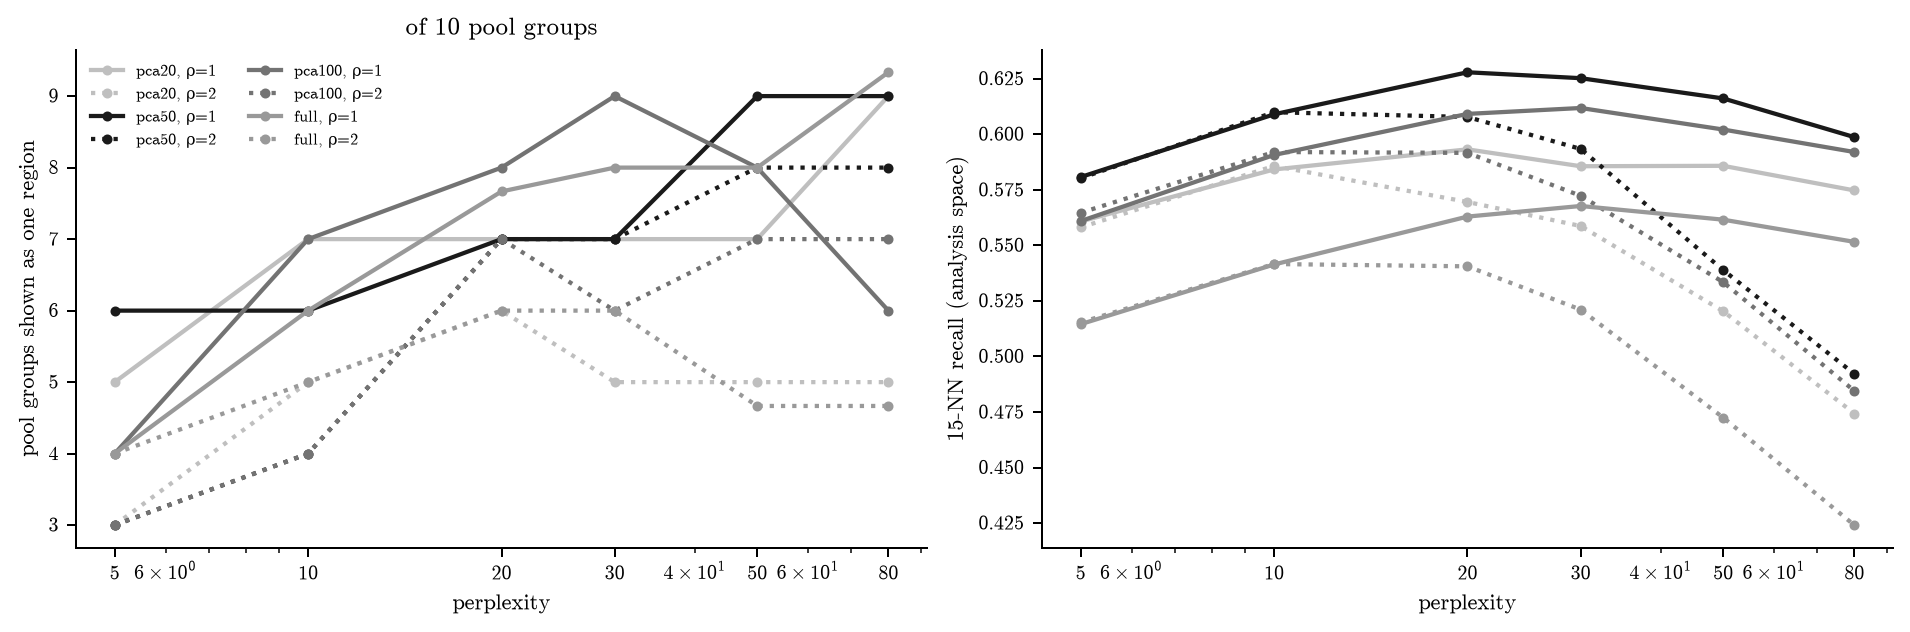

Chosen: pca50-p50-x1 (recall floor 0.597)


,key,input,perplexity,exaggeration,agree,covered,recall15_analysis,recall15_full,regions,unassigned,agree_min,agree_max,eligible
46,full-p80-x1,full,80,1,9.333,220.667,0.552,0.471,46.0,337.667,9,10,False
20,pca50-p50-x1,pca50,50,1,9.000,192.000,0.616,0.483,53.0,220.000,9,9,True
30,pca100-p30-x1,pca100,30,1,9.000,192.000,0.612,0.493,57.0,209.000,9,9,True
22,pca50-p80-x1,pca50,80,1,9.000,260.000,0.599,0.470,43.0,160.000,9,9,True
10,pca20-p80-x1,pca20,80,1,9.000,192.000,0.575,0.452,45.0,189.000,9,9,False
28,pca100-p20-x1,pca100,20,1,8.000,174.000,0.609,0.495,58.0,124.000,8,8,True
32,pca100-p50-x1,pca100,50,1,8.000,174.000,0.602,0.485,52.0,176.000,8,8,True
42,full-p30-x1,full,30,1,8.000,174.000,0.568,0.496,44.0,185.333,8,8,False
44,full-p50-x1,full,50,1,8.000,174.000,0.562,0.483,45.0,254.667,7,9,False
21,pca50-p50-x2,pca50,50,2,8.000,174.000,0.539,0.429,52.0,229.000,8,8,False


In [4]:
sw = C["sweep"]
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.4))
for name, color in zip(config["sweep"]["inputs"], ["0.75", "0.1", "0.45", "0.6"]):
    for rho, ls in [(1, "-"), (2, ":")]:
        s = sw[(sw.input == name) & (sw.exaggeration == rho)].sort_values("perplexity")
        axes[0].plot(s.perplexity, s.agree, ls=ls, marker="o", ms=3, color=color, label=f"{name}, ρ={rho}")
        axes[1].plot(s.perplexity, s.recall15_analysis, ls=ls, marker="o", ms=3, color=color)
axes[0].set(xscale="log", xlabel="perplexity", ylabel="pool groups shown as one region", title=f"of {int(groups.pool.sum())} pool groups")
axes[1].set(xscale="log", xlabel="perplexity", ylabel="15-NN recall (analysis space)")
for ax in axes:
    ax.set_xticks(config["sweep"]["perplexities"], config["sweep"]["perplexities"])
axes[0].legend(fontsize=6.5, ncol=2)
fig.savefig(FIGURES / "display-sweep.png", dpi=200)
plt.show()
floor = config["sweep"]["recall_floor"] * sw.recall15_analysis.max()
view = sw.assign(eligible=sw.recall15_analysis >= floor).sort_values(["agree", "recall15_analysis"], ascending=False)
print(f"Chosen: {CHOSEN} (recall floor {floor:.3f})")
view.head(12).round(3)

## 4. Consensus map

Each group is drawn as an outline of its members. The outline is a sum of isotropic Gaussian kernels, with one bandwidth shared by all groups (1.5 × the map's median nearest-neighbour distance). It is cut at the level that keeps 90% of the members inside, then halved so that the line clears them. Because the bandwidth is shared, every group gets the same padding, and separated clumps of one group stay apart. A group that splits on the map therefore shows as several islands. A per-group bandwidth, as used by the 50/80% mass contours of the earlier explorers and panel (a) below, joins such clumps into elongated shapes.

Outlines show where the members are drawn. They are not probability regions, and they are not cluster boundaries in the map. Tier 1 groups are lightly filled and outlined; tier 2 groups are dashed. Each label sits just outside its outline, in the least crowded of 16 positions. The frame is fitted to the map rather than square, because a square frame here leaves much of the panel blank. A square version is saved as well.

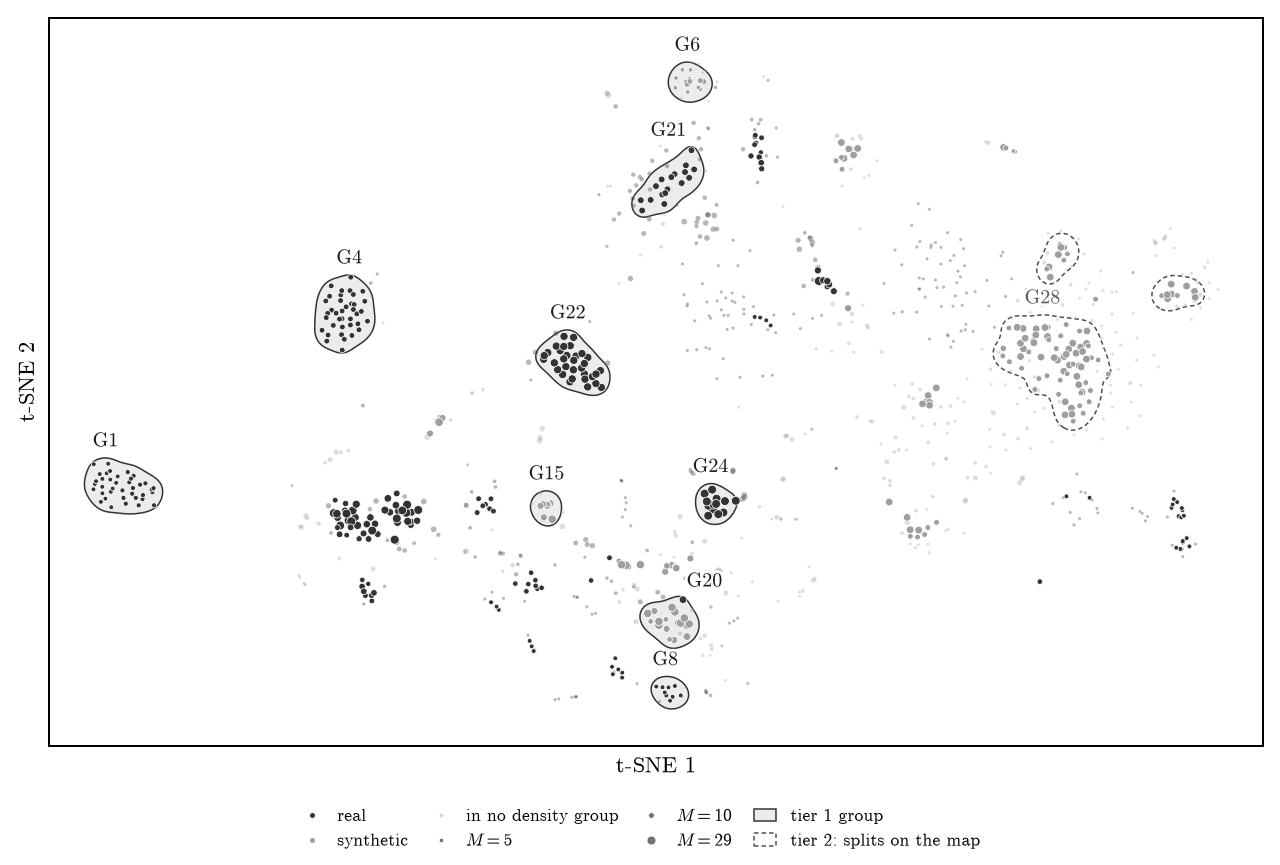

/Users/wedi0306/Code/mts-spi-study-cluster/results/zenodo_7118947/consensus-261024/figures: consensus-map (tier 1), consensus-map-pool (shown), consensus-map-pool-square, consensus-map-all-groups


In [5]:
tier = dict(zip(groups.group, groups.tier))
tier1 = [g for g in groups.group if tier[g] == 1]
tier2 = [g for g in groups.group if tier[g] == 2]
faint = density < 0
span = xy.max(0) - xy.min(0)
aspect = span[1] / span[0]

def consensus_figure(name, filled, dashed=(), *, width=7.0, square=False, annotate=True,
                     legend=("tier 1 group", "tier 2: splits on the map"), **style):
    fig, ax = plt.subplots(figsize=(width, width * (1 if square else aspect) + .9))
    ca.plot_consensus(ax, xy, meta, density, filled, dashed, square=square, annotate=annotate, **style)
    ta.atlas_legend(fig, meta, size=.8, filled=legend[0] if filled else None, dashed=legend[1] if dashed else None)
    for ext in ["svg", "pdf", "png"]:
        fig.savefig(FIGURES / f"{name}.{ext}", dpi=600 if ext == "png" else None)
    return fig

for name, filled, dashed, options in [
        ("consensus-map", tier1, (), {}),
        ("consensus-map-pool-square", tier1, tier2, {"square": True}),
        ("consensus-map-all-groups", [], list(groups.group), {"annotate": False, "legend": (None, "density group")})]:
    plt.close(consensus_figure(name, filled, dashed, **options))
consensus_figure("consensus-map-pool", tier1, tier2)
plt.show()
print(f"{FIGURES}: consensus-map (tier 1), consensus-map-pool (shown), consensus-map-pool-square, consensus-map-all-groups")

Styles compared on the same map: (a) the previous drawing, 50% and 80% mass KDE contours with a per-group bandwidth and a faint fill; (b) fill only; (c) outline only; (d) fill and outline, as above. (e) shows every density group outlined, which makes the continuum's segmentation visible.

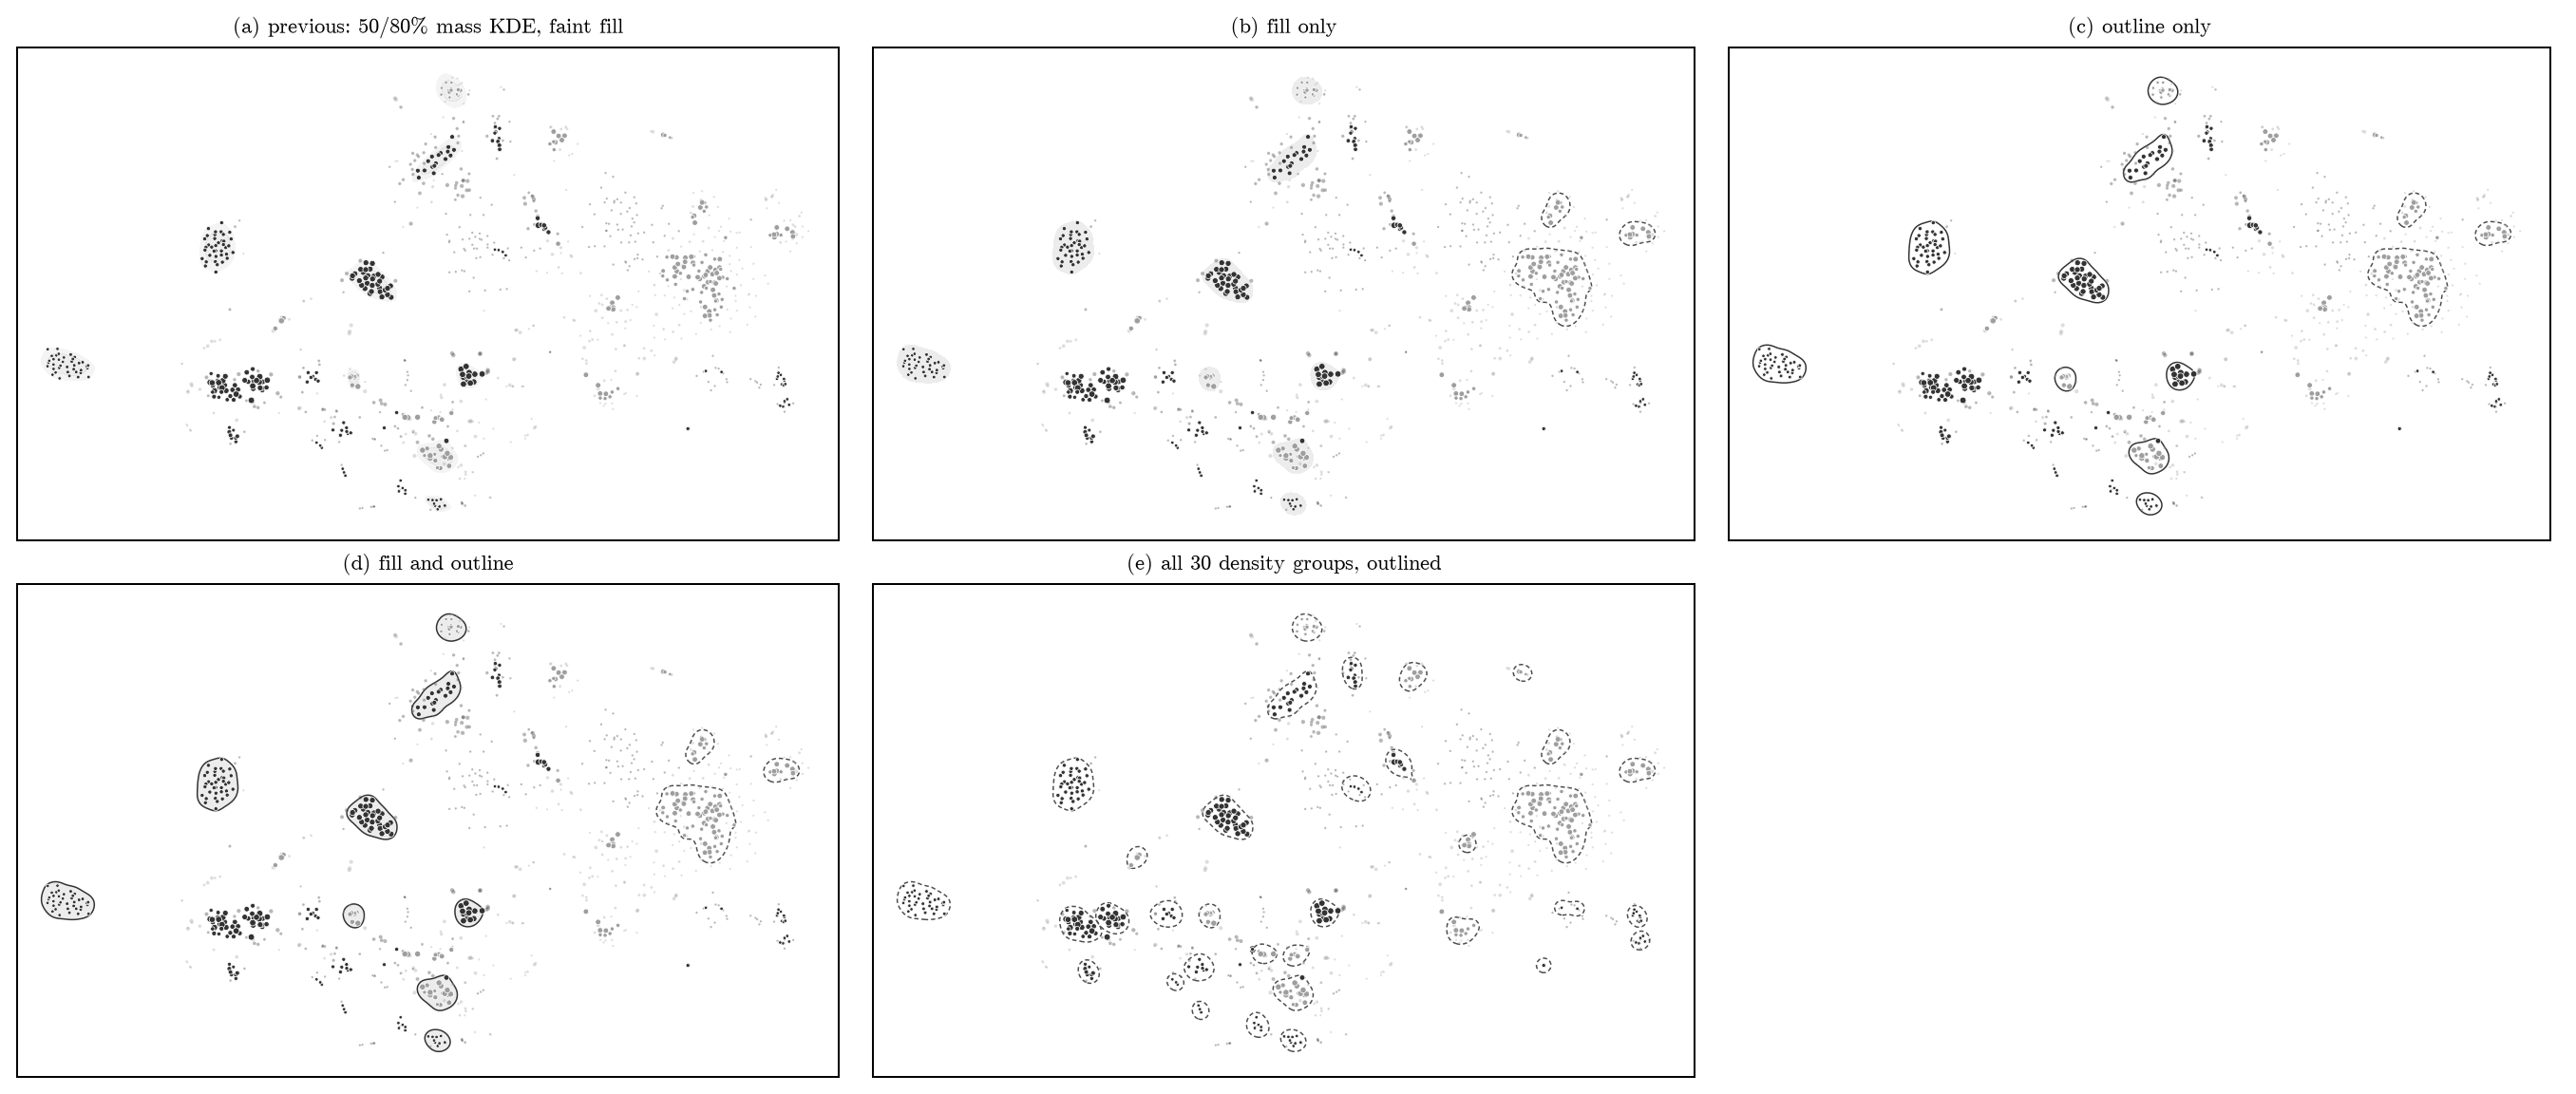

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(15, 2 * 5 * aspect + .6))
ta.plot_atlas(axes[0, 0], xy, meta, density, {g: "" for g in tier1}, faint=faint, size=.45, annotate=False, square=False)
axes[0, 0].set_title("(a) previous: 50/80% mass KDE, faint fill", fontsize=9)
for ax, (title, style) in zip(axes.flat[1:4], [("(b) fill only", {"line": False}), ("(c) outline only", {"fill": False}),
                                               ("(d) fill and outline", {})]):
    ca.plot_consensus(ax, xy, meta, density, tier1, tier2, size=.45, annotate=False, **style)
    ax.set_title(title, fontsize=9)
ca.plot_consensus(axes[1, 1], xy, meta, density, [], list(groups.group), size=.45, annotate=False)
axes[1, 1].set_title(f"(e) all {len(groups)} density groups, outlined", fontsize=9)
axes[1, 2].axis("off")
for ax in axes.flat[:5]:
    ax.set(xlabel="", ylabel="")
plt.show()

## 5. The candidate pool, group by group

Each row: the group on the map (left), then up to six member heatmaps. Members are the medoid, then round-robin over source families, nearest to the medoid first, so that differently looking members are included. Tier 3 groups follow more compactly, for completeness.

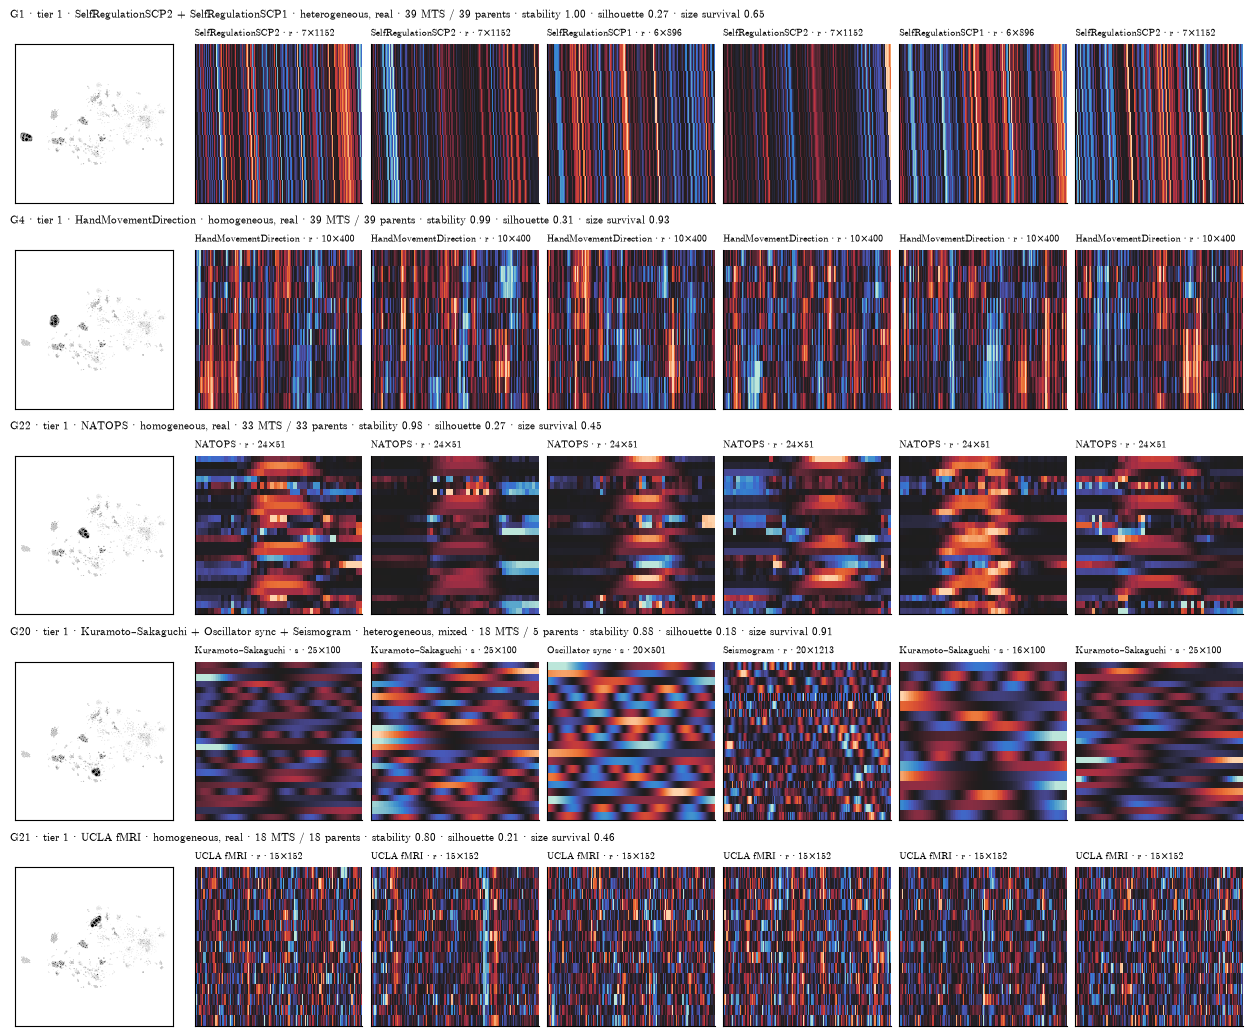

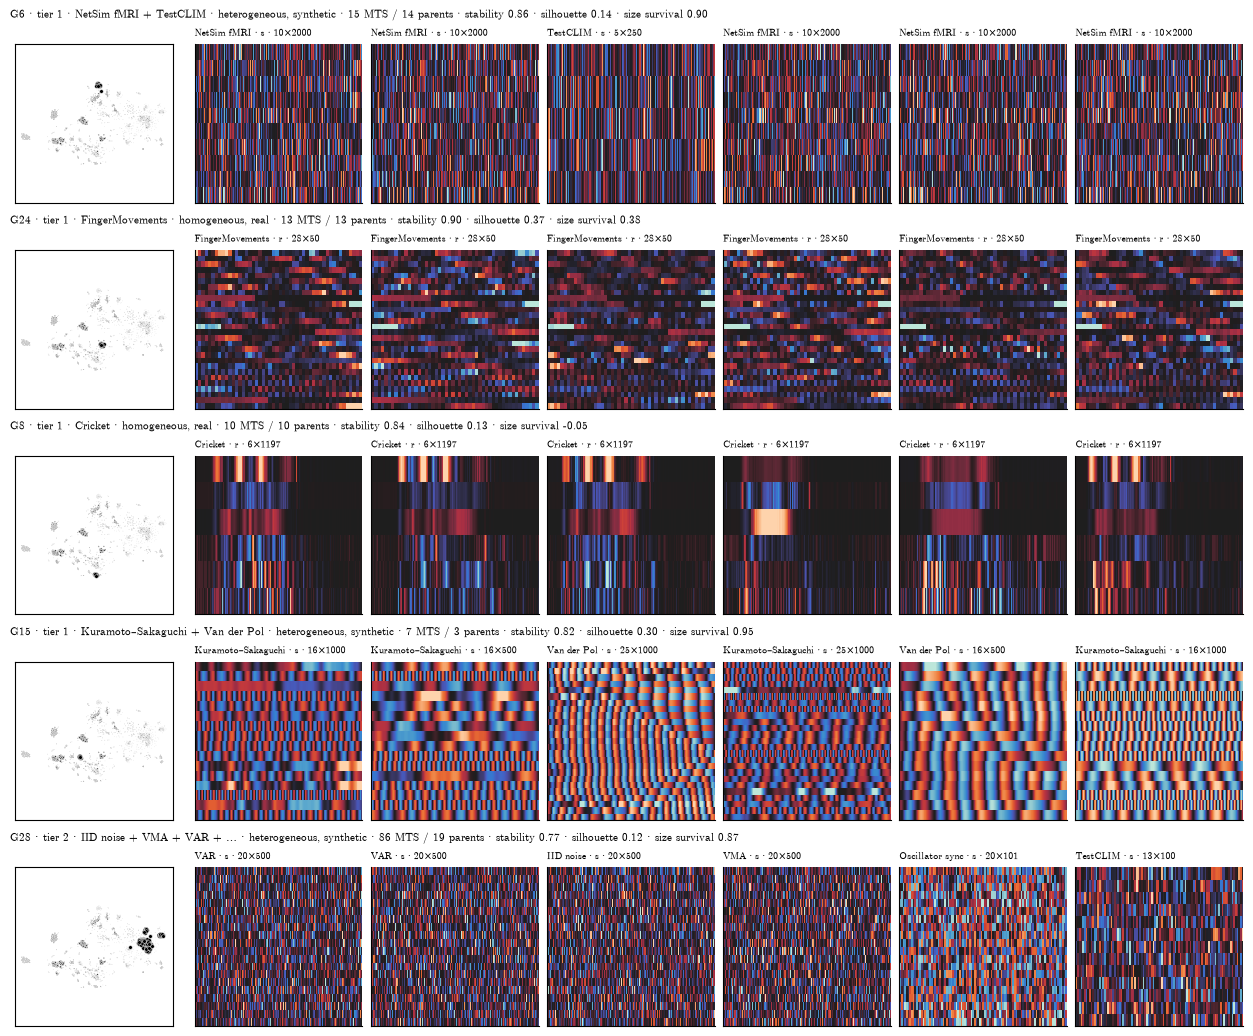

In [7]:
D = A["full_distances"]
def group_rows(gs, n=6, width=12.5):
    for chunk in [gs[i:i + 5] for i in range(0, len(gs), 5)]:
        fig = plt.figure(figsize=(width, 2.05 * len(chunk)), dpi=100)
        sub = fig.subfigures(len(chunk), 1, squeeze=False)[:, 0]
        for sf, g in zip(sub, chunk):
            info = groups.set_index("group").loc[g]
            members = np.flatnonzero(density == g)
            reps = ta.representatives(members, D, meta, n=n)
            axes = sf.subplots(1, n + 1, gridspec_kw={"width_ratios": [1.1] + [1] * n})
            ta.draw_groups(axes[0], xy, density, [g])
            ta.plot_atlas(axes[0], xy, meta, annotate=False, shade=False, size=.12, faint=faint)
            axes[0].scatter(*xy[members].T, s=7, c="k", edgecolors="white", linewidths=.3, zorder=4)
            sf.suptitle(f"G{g} · tier {info.tier} · {info.title} · {info.composition}, {info.origin} · {info['size']} MTS / {info.parents} parents · "
                        f"stability {info.stability:.2f} · silhouette {info.silhouette_full:.2f} · size survival {info.size_survival:.2f}",
                        fontsize=8, x=.01, ha="left")
            for ax, r in zip(axes[1:], reps):
                m = meta.iloc[r]
                ta.heatmap(ax, corpus["arrays"][m.dataset], f"{m.source} · {m.origin[0]} · {m['M']}×{m['T']}")
            for ax in axes[1 + len(reps):]:
                ax.axis("off")
        plt.show()

group_rows([g for g in groups.group if tier[g] <= 2])

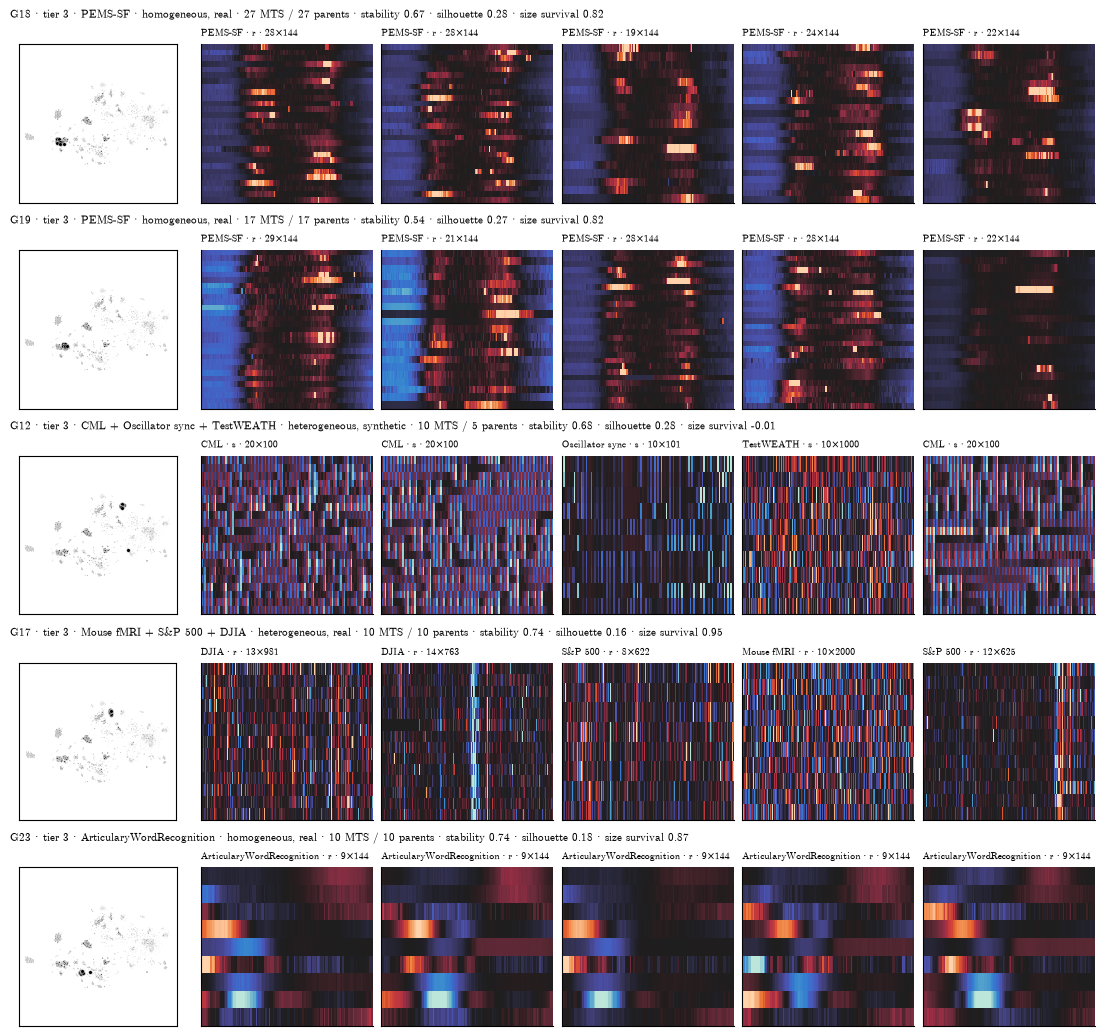

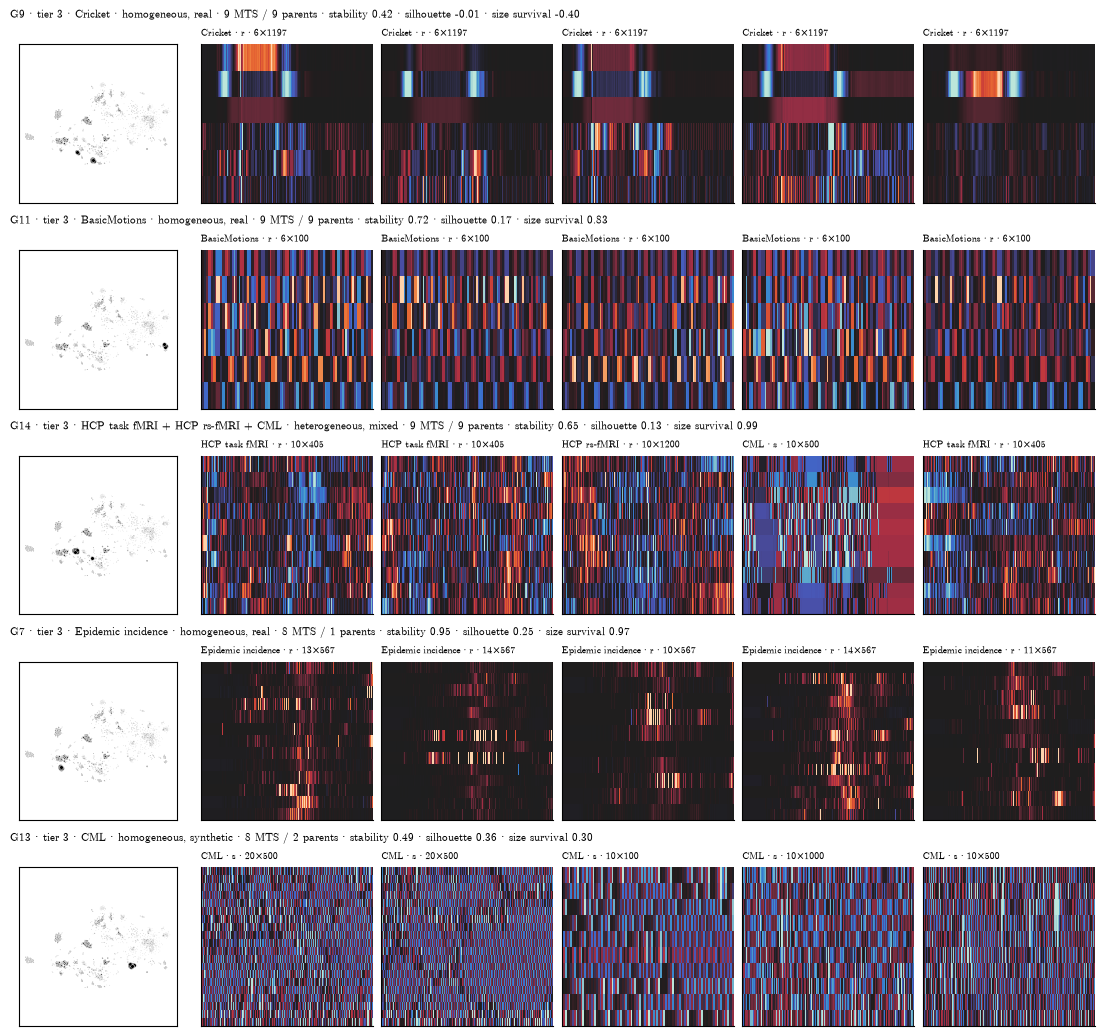

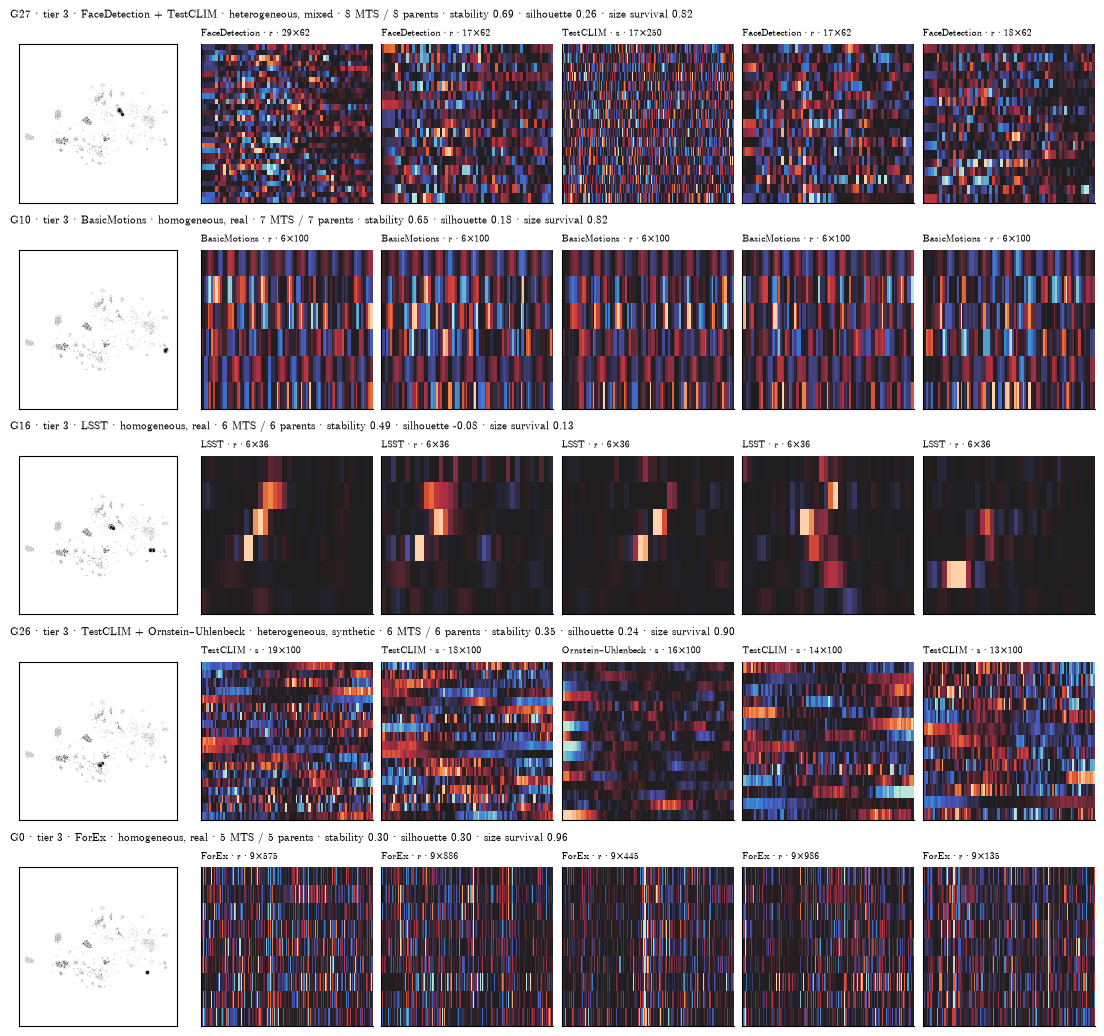

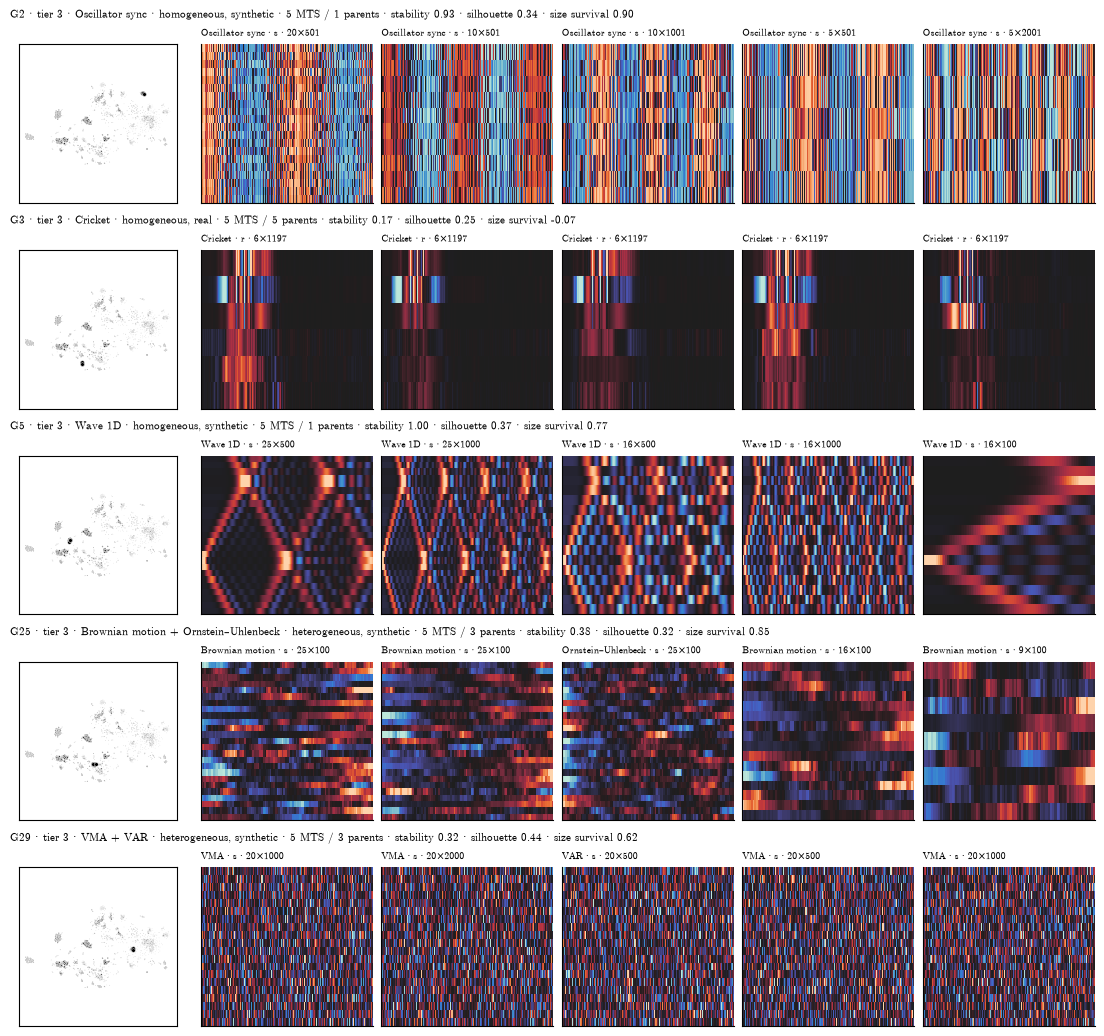

In [8]:
group_rows([g for g in groups.group if tier[g] == 3], n=5, width=11)

## 6. Signatures

Median z of the case-study SPI pairs and raw-series descriptors for the candidate pool, next to the corpus medians. The raw descriptors are lag-1 autocorrelation, linear-trend R², the share of negative r among each recording's strongest edges, the first-PC variance share, the share of repeated consecutive values, and the maximum robust |z|. They are transparent checks on a reading, not features of the representation.

In [9]:
pool = [g for g in groups.group if tier[g] <= 2]
axes_z = ta.case_axes(corpus["raw"], corpus["spis"])
raw = pd.DataFrame([ta.raw_descriptors(corpus["arrays"][n]) for n in meta.dataset])
sig = pd.concat({"case axes (median z)": pd.DataFrame({f"G{g}": axes_z[density == g].median() for g in pool}).T,
                 "raw series (median)": pd.DataFrame({f"G{g}": raw[density == g].median() for g in pool}).T}, axis=1)
corpus_row = pd.concat({"case axes (median z)": axes_z.median(), "raw series (median)": raw.median()}).to_frame("corpus").T
sig = pd.concat([sig, corpus_row])
sig.insert(0, "title", [groups.set_index("group").title.get(int(i[1:]), "") if i != "corpus" else "" for i in sig.index])
sig.round(2)

title     case axes (median z)                                                                                                                                   \
                                                          r–ρ (linear vs monotone) r–MI (linear vs general) r–max xcorr (zero lag vs best lag) r–coherence (time vs frequency) Euclid–DTW (aligned vs warped shape)   
G1                SelfRegulationSCP2 + SelfRegulationSCP1                     1.00                     0.96                               0.76                            0.63                                 0.61   
G4                                  HandMovementDirection                     1.00                     0.93                               0.99                            0.86                                 0.90   
G22                                                NATOPS                     0.98                     0.29                               0.78                            0.38                                 0.92   
G20     Kuramoto–Sakaguchi + Oscillator sync + Seismogram                     0.98                     0.00                               0.19                           -0.03                                 0.56   
G21                                             UCLA fMRI                     0.99                     0.73                               0.88                            0.80                                 0.71   
G6                                 NetSim fMRI + TestCLIM                     1.00                     0.95                               1.00                            0.92                                 0.12   
G24                                       FingerMovements                     0.94                     0.04                               0.70                            0.22                                 0.67   
G8                                                Cricket                     0.95                    -0.43                               0.70                           -0.27                                 0.69   
G15                      Kuramoto–Sakaguchi + Van der Pol                     0.99                     0.60                               0.46                            0.04                                 0.43   
G28                             IID noise + VMA + VAR + …                     0.95                     0.03                               0.04                           -0.00                                 0.05   
corpus                                                                        0.97                     0.30                               0.59                            0.26                                 0.54   

       raw series (median)                                                                        
                      lag1 trend_r2 negative_share_strong pc1_share repeat_fraction max_robust_z  
G1                    0.98     0.10                  0.00      0.57            0.01         3.65  
G4                    0.91     0.03                  0.00      0.65            0.00         3.64  
G22                   0.96     0.07                  0.13      0.61            0.00         8.68  
G20                   1.00     0.02                  0.48      0.29            0.00         3.57  
G21                   0.41     0.00                  0.00      0.37            0.00         4.15  
G6                    0.36     0.00                  0.00      0.36            0.00         4.46  
G24                   0.72     0.19                  0.51      0.28            0.00        13.81  
G8                    0.99     0.08                  0.75      0.40            0.24        30.83  
G15                   1.00     0.00                  0.30      0.22            0.00         1.95  
G28                  -0.00     0.00                  0.50      0.11            0.00         4.25  
corpus                0.55     0.01                  0.31      0.37 

In [10]:
keep = A["keep_indices"]
families = {}
for g in pool:
    frame = ta.contrasts(corpus["raw"], keep, np.flatnonzero(density == g), corpus["pairs"], corpus["spis"])
    up, down = ta.family_summary(frame, top=2)
    families[f"G{g}"] = {"higher agreement than corpus": "; ".join(f"{k} {v:+.2f}" for k, v in up.items()),
                         "lower agreement": "; ".join(f"{k} {v:+.2f}" for k, v in down.items())}
pd.DataFrame(families).T

,higher agreement than corpus,lower agreement
G1,basic × spectral +0.45; basic × basic +0.44,basic × causal -1.27; causal × infotheory -0.60
G4,basic × basic +0.67; basic × spectral +0.58,basic × causal -1.31; causal × spectral -0.63
G22,basic × basic +0.18; causal × distance +0.13,causal × spectral -0.42; basic × causal -0.30
G20,causal × misc +0.31; causal × spectral +0.27,basic × causal -0.43; basic × spectral -0.25
G21,causal × infotheory +0.11; causal × misc +0.10,basic × causal -0.14; basic × basic -0.13
G6,causal × spectral +0.21; basic × causal +0.18,basic × basic -0.32; misc × spectral -0.23
G24,basic × causal +0.36; infotheory × infotheory +0.24,causal × infotheory -0.40; causal × spectral -0.13
G8,basic × causal +0.46; infotheory × infotheory +0.23,causal × misc -0.47; spectral × spectral -0.41
G15,basic × basic +0.68; causal × spectral +0.35,basic × causal -1.16; basic × spectral -0.28
G28,basic × causal +0.53; causal × spectral +0.47,basic × basic -0.49; basic × spectral -0.31


### Readings of the candidate pool

Numbers refer to the tables above (case axes are median z; raw descriptors are medians). Readings name the shared organisation, not a mechanism; where a reading goes beyond the numbers it is marked as inference.

**Tier 1, homogeneous by source**
- **G4 · HandMovementDirection MEG (39).** Every case axis is high: r–max xcorr 0.99, r–coherence 0.86, Euclid–DTW 0.90. Channels are smooth (lag-1 0.91) and no strong edge is negative. Reading: positive, contemporaneous, linear dependence that every statistic family reports alike. Size explains little of it (survival 0.93).
- **G22 · NATOPS (33).** Aligned and warped shape similarity agree (Euclid–DTW 0.92). This is the only source at 24 × 51, and size-matched sets account for about half its cohesion (survival 0.45). Disclose that.
- **G21 · UCLA fMRI (18).** Linear and general dependence agree (r–MI 0.73, r–coherence 0.80) at modest autocorrelation (lag-1 0.41). Survival is 0.46.
- **G6 · NetSim fMRI (14, plus one TestCLIM series).** The four r-based axes are near 1 and no strong edge is negative: linear, contemporaneous, positive dependence. Survival is 0.90.
- **G24 · FingerMovements EEG (13).** Half the strongest edges are negative (0.51 vs 0.31), and signed r disagrees with unsigned MI (r–MI 0.04). Reading: anti-correlated channel pairs. Survival is 0.38.
- **G8 · Cricket (10): cautionary.** Same-size sets from other sources are as cohesive (survival −0.05, p 0.90), so its compactness is not evidence of a source-specific signature.

**Tier 1, more than one source**
- **G1 · SelfRegulationSCP1 and SCP2 EEG (19 + 20).** Two datasets from one slow-cortical-potential paradigm, so this is close to homogeneous. Smooth (lag-1 0.98) and positive; directed spectral measures in different bands disagree with each other (z −0.72 vs 0.61 corpus-wide). Survival is 0.65.
- **G15 · Kuramoto–Sakaguchi and Van der Pol oscillators (5 + 2, three generator configurations).** Different oscillator models share one organisation. Signals are smooth (lag-1 1.00) but zero-lag correlation does not track coherence (r–coherence 0.04) and only partly tracks best-lag correlation (0.46). Time-domain and spectral Granger causality disagree (z −0.43 against 0.97 corpus-wide). Reading (inference): coupling carried at a phase lag, which the zero-lag and time-domain measures miss. Survival is 0.95. This is the clearest cross-model synthetic example in the pool.
- **G20 · Kuramoto–Sakaguchi (16, five configurations) with one phase-synchrony oscillator window and one seismogram.** Same reading, more extreme: r–MI 0.00, r–max xcorr 0.19, r–coherence −0.03, and half the strong edges negative. The single seismogram (Puerto Rico) sitting in it is an odd one out worth inspecting.

**Tier 2**
- **G28 · Uncoupled and linear-Gaussian processes (86): IID noise, VAR, VMA, strongly coupled phase oscillators.** Every case axis is near 0 (r–max xcorr 0.04, Euclid–DTW 0.05), with no autocorrelation and no common mode (first-PC share 0.11). This is the "little or no dependence" region. It is stable (0.77) but spreads over several map regions (67% in one).

**Near misses** (at least 3 parents, stability 0.65–0.75; outside the pool by the fixed rule)
- **G17 · Mouse fMRI (5 subjects) with S&P 500 and DJIA log-returns (5 windows).** Stability 0.74 misses the cutoff by 0.01, which is within the resampling error of a 50-replicate estimate (about ±0.03). It is one map region (100%), and size explains none of its cohesion (survival 0.95). Signature: linear, contemporaneous, positive dependence (r–MI 0.88, r–max xcorr 0.99, r–coherence 0.91) between temporally white signals (lag-1 −0.03). Reading (inference): a common instantaneous factor on top of white fluctuations, such as a market factor in returns or a global signal in fMRI. It is the strongest real–real cross-mechanism example found.
- **G14 · HCP task and resting fMRI (4 + 4) with one lattice window.** Stability 0.65, survival 0.99.
- **G27 · FaceDetection MEG (7) with one TestCLIM series.** Stability 0.69.
- **G18, G19 · PEMS-SF traffic days.** Stability 0.67 and 0.54.

**What changes.** Under these criteria the pool is mostly source families. Two candidates are cross-model and survive every test: oscillators (G15, G20) and, at the stability margin, mouse fMRI with stock returns (G17). The 21 October mixed candidates (trending series, traffic with LEGION, CML with weather) do not form density cores (section 7). They remain real co-locations in the continuum, at weaker separation.

## 7. Where the 21 October candidates went

The earlier lettered Ward candidates against the new pool. "In density groups" is the share of members assigned to any density group; the last column names the density groups holding them.

In [11]:
ward = A["partition__ward40"]
old = {35: "A NATOPS", 21: "B NetSim", 20: "C CML + TestWEATH", 4: "D Cricket + ForEx", 34: "E PEMS-SF + LEGION + GBM",
       39: "F trending series", 6: "G heavy-tailed noise + TestWEATHmiss"}
rows = []
for c, name in old.items():
    m = ward == c
    held = pd.Series(density[m & (density >= 0)]).value_counts()
    rows.append({"earlier candidate": name, "size": int(m.sum()), "in density groups": float(np.mean(density[m] >= 0)),
                 "density groups (members, tier)": "; ".join(f"G{g}: {n} (t{tier[g]})" for g, n in held.items())})
pd.DataFrame(rows).round(2)

,earlier candidate,size,in density groups,"density groups (members, tier)"
0,A NATOPS,36,0.92,G22: 33 (t1)
1,B NetSim,20,0.70,G6: 14 (t1)
2,C CML + TestWEATH,25,0.40,G12: 10 (t3)
3,D Cricket + ForEx,15,0.67,G8: 10 (t1)
4,E PEMS-SF + LEGION + GBM,41,0.63,G18: 26 (t3)
5,F trending series,37,0.41,G23: 10 (t3); G9: 4 (t3); G14: 1 (t3)
6,G heavy-tailed noise + TestWEATHmiss,32,0.28,G28: 9 (t2)


## 8. Explorer v4

`results/zenodo_7118947/consensus-261024/index.html`, rendered from `research/zenodo/atlas/zenodo_gallery_v4.html`. It is self-contained apart from the native heatmap links, which need `results/zenodo_7118947/visual-exploration/` beside it. It offers four maps: the chosen consensus map, the 21 October full-rank map, the visually cleanest low-perplexity map from the sweep, and PC1–PC2. Each map carries its own count of groups that appear as one region. It leads with the map regions of the neighbourhood analysis: candidate regions are shaded and listed by default, with composition (members and parent recordings per source), validation statistics and signatures. Region kinds and candidates come from `neighbourhood_atlas.classify_regions`, the rule behind that notebook's candidate map. Density groups are listed by tier with heatmap strips and signatures. Each recording's detail lists its 10 nearest other-parent neighbours in PCA50, and lines show where they land on the map. The page reads the neighbourhoods cache, computed below if missing.

In [12]:
NOTES = {  # short readings for the explorer, from section 6
    4: "Positive, contemporaneous, linear dependence reported alike by every statistic family; size explains little (survival 0.93).",
    22: "Aligned and warped shape similarity agree; only source at 24 × 51, and size-matched sets account for about half its cohesion.",
    21: "Linear and general dependence agree at modest autocorrelation.",
    6: "Linear, contemporaneous, positive dependence; the four r-based axes are near 1.",
    24: "Half the strongest edges negative; signed r disagrees with unsigned MI: anti-correlated channel pairs.",
    8: "Cautionary: size-matched sets from other sources are as cohesive, so its compactness is not source-specific.",
    1: "Two datasets of one slow-cortical-potential paradigm: smooth, positive, directed spectral measures disagree across bands.",
    15: "Different oscillator models, one organisation: smooth signals, zero-lag r does not track coherence, time and spectral Granger disagree (inference: phase-lagged coupling).",
    20: "Phase-lagged oscillator coupling, more extreme than G15: r carries none of the MI or coherence; one seismogram is an odd one out.",
    28: "Little or no dependence: every case axis near 0, no autocorrelation, no common mode. Stable but spread over several map regions.",
    17: "Near miss (stability 0.74). Mouse fMRI with stock log-returns: linear, contemporaneous, positive dependence between temporally white signals (inference: a common instantaneous factor).",
    14: "Near miss (stability 0.65). HCP task and resting fMRI with one lattice window.",
}

In [13]:
from research.zenodo.atlas import neighbourhood_atlas as na

ncfg = yaml.safe_load(na.CONFIG.read_text())
NOUT = ROOT / ncfg["output"]
if not (NOUT / "manifest.json").exists():
    with threadpool_limits(limits=ncfg["threads"]):
        na.compute(ncfg, NOUT)  # about 2 minutes; reads the consensus cache
NB = na.load(NOUT)
regions = NB["arrays"]["regions"]
assert (regions == C["arrays"]["chosen_regions"]).all() and NB["manifest"]["chosen_map"] == CHOSEN
assert ncfg["analysis_dims"] == config["analysis_dims"]
R = na.classify_regions(NB["regions"], pd.Series(tier))  # the rule behind the neighbourhoods notebook's candidate map
REGION_NOTES = {  # short readings for the explorer, from section 7 of zenodo_1053_neighbourhoods_261024
    11: "Common instantaneous factor (inference): every r-based case axis near 1, no strong negative edges, temporally white channels. The same market windows as price levels sit in R28.",
    34: "Phase-lagged oscillation (inference): smooth signals, and zero-lag r does not track coherence. Kuramoto and Van der Pol also share simulation toolbox and size grid (ground-truth notebook), so this is weaker evidence for a shared coupling form than it looks.",
    38: "Lagged or anti-phase oscillatory relations (inference): r carries little of MI or coherence, and half the strong edges are negative. The seismograms are 3 of 36 members; stability is at the floor of Hennig's pattern band.",
    28: "Co-trending: persistent, trending channels whose contemporaneous and best-lag correlations agree. A nonstationary regime rather than a coupling form (Yule 1926). The same market windows as log-returns sit in R11.",
    27: "HCP task and resting fMRI with four visitors: one acquisition programme, so weak evidence against the dataset objection.",
    43: "Linear-stochastic processes (VAR, VMA, TestWEATH): little or no dependence, with every case axis near 0.",
    51: "Little or no dependence (about G28): stable and size-robust, but what is shared is the absence of structure.",
    0: "Two datasets from one slow-cortical-potential paradigm: a same-source check, not cross-domain evidence.",
    6: "A NATOPS core with two LSST and one TestCLIM visitor; size explains about half its tightness (survival 0.48).",
    5: "Cautionary: tight and multi-source, but size-matched sets from other sources are as cohesive (survival −0.03).",
}
num = lambda v: None if pd.isna(v) else float(v)
region_records = []
for r in R.to_dict("records"):
    m = regions == r["region"]
    members = np.flatnonzero(m)
    region_records.append({
        "id": int(r["region"]), "title": r["title"], "kind": r["kind"], "priority": r["priority"], "candidate": bool(r["candidate"]),
        "size": int(r["size"]), "parents": int(r["parents"]), "origin": r["origin"], "M": r["M"], "T": r["T"],
        **{k: num(r[k]) for k in ["stability", "recurs_share", "cohesion_z", "p_random", "size_survival", "p_matched", "nn_inside",
                                  "cross_members"]},
        "medoid": int(members[np.argmin(D[np.ix_(members, members)].sum(axis=1))]),
        "reps": [int(i) for i in ta.representatives(members, D, meta, n=4)], "note": REGION_NOTES.get(int(r["region"]), ""),
        "axes": [{"axis": a, "cluster": num(axes_z[m][a].median()), "corpus": float(axes_z[a].median())} for a in ta.CASE_AXES],
        "raw": {k: num(v) for k, v in raw[m].median().items()}})
# Each recording's 10 nearest neighbours from other parent recordings in the analysis space: the k = 10 edges used there.
src, dst = NB["arrays"]["edges_k10"]
assert (src == np.repeat(np.arange(len(meta)), 10)).all()
S = A["scores_primary"][:, :config["analysis_dims"]]
nn, nn_d = dst.reshape(-1, 10), np.linalg.norm(S[src] - S[dst], axis=1).reshape(-1, 10)
siblings = meta.parent.map(meta.parent.value_counts()).to_numpy() - 1
print(f"{int(R.candidate.sum())} candidate regions: " + ", ".join(f"R{r}" for r in R.region[R.candidate])
      + f"; kinds: {R.kind.value_counts().to_dict()}; median nearest-neighbour distance {np.median(nn_d[:, 0]):.1f}")


10 candidate regions: R0, R5, R6, R11, R27, R28, R34, R38, R43, R51; kinds: {'map-only': 23, 'neighbourhood': 20, 'core': 6, 'one parent': 4}; median nearest-neighbour distance 16.4


In [14]:
def entry(key, xy_map, title):
    regions = ta.map_clusters(xy_map, **config["map_regions"])
    agree, _ = ca.map_agreement(xy_map, density, groups.group, config["agreement"]["modal_share"], config["agreement"]["region_share"],
                                config["map_regions"])
    shown = [int(g) for g in groups.group if agree[g][3]]
    n_pool = sum(tier[g] <= 2 for g in shown)
    return {"title": title, "xy": np.round(xy_map, 4).tolist(), "regions": regions.tolist(), "agree": shown,
            "axis_labels": ["PC1", "PC2"] if key == "pca" else ["t-SNE 1", "t-SNE 2"],
            "note": f"{n_pool} of {int(groups.pool.sum())} pool groups appear as one region; {regions.max() + 1} map regions"}

clean = sw.sort_values(["perplexity", "exaggeration"], ascending=[True, False]).iloc[0].key  # most fragmented map in the sweep
maps = {"chosen": entry("chosen", xy, f"Chosen · {CHOSEN} (most pool groups as single regions within the recall floor)"),
        "v3": entry("v3", A["map__primary-p30-x1-pca"][0], "21 October map · full rank, perplexity 30, ρ = 1"),
        "clean": entry("clean", C["arrays"][f"map__{clean}"][0], f"Visually fragmented · {clean} (not recommended)"),
        "pca": entry("pca", A["scores_primary"][:, :2], "Linear reference · PC1–PC2")}
assert maps["chosen"]["regions"] == regions.tolist()
radii = ta.marker_radii(meta["M"].to_numpy(), meta["M"].min(), meta["M"].max())
legend = sorted({int(meta["M"].min()), int(meta["M"].median()), int(meta["M"].max())})
info = groups.set_index("group")
records = []
for g in groups.group:
    members = np.flatnonzero(density == g)
    frame = ta.contrasts(corpus["raw"], keep, members, corpus["pairs"], corpus["spis"])
    up, down = ta.family_summary(frame, top=2)
    i = info.loc[g]
    records.append({"id": int(g), "title": i.title, "tier": int(i.tier), "composition": i.composition, "origin": i.origin,
                    "cross_source": bool(i.cross_source), "size": int(i["size"]), "parents": int(i.parents), "sources": i.source_mix,
                    "M": i.M, "T": i["T"], "stability": float(i.stability), "silhouette_full": float(i.silhouette_full),
                    "silhouette_pca": float(i.silhouette_pca), "size_survival": float(i.size_survival), "p_matched": float(i.p_matched),
                    "in_modal_region": float(i.in_modal_region),
                    "medoid": int(members[np.argmin(D[np.ix_(members, members)].sum(axis=1))]),
                    "reps": [int(r) for r in ta.representatives(members, D, meta, n=4)], "note": NOTES.get(int(g), ""),
                    "families": f"higher agreement: {'; '.join(f'{k} {v:+.2f}' for k, v in up.items())}; lower: {'; '.join(f'{k} {v:+.2f}' for k, v in down.items())}",
                    "axes": [{"axis": a, "cluster": None if np.isnan(v := float(axes_z[density == g][a].median())) else v,
                              "corpus": float(axes_z[a].median())} for a in ta.CASE_AXES],
                    "raw": {k: float(v) for k, v in raw[density == g].median().items()}})
payload = {"rows": [{"row": int(r.row), "dataset": r.dataset, "M": int(r.M), "T": int(r.T), "origin": r.origin, "source": r.source,
                     "parent": r.parent, "tags": json.loads(r.tags), "group": int(density[r.row]), "marker_radius": float(radii[r.row]),
                     "nn": nn[r.row].tolist(), "nn_d": np.round(nn_d[r.row], 2).tolist(), "siblings": int(siblings[r.row])}
                    for r in meta.itertuples()],
           "maps": maps, "default_map": "chosen", "groups": records, "regions": region_records, "region_map": "chosen",
           "nn_scale": round(float(np.median(nn_d[:, 0])), 2),
           "corpus_raw": {k: float(v) for k, v in raw.median().items()},
           "size_legend": [{"M": m, "radius": float(ta.marker_radii(m, meta["M"].min(), meta["M"].max()))} for m in legend],
           "origin_styles": {"real": {"fill": "#333333", "stroke": "#ffffff"}, "synthetic": {"fill": "#9e9e9e", "stroke": "#ffffff"},
                             "unlabelled": {"fill": "none", "stroke": "#555555"}},
           "origin_counts": meta.origin.value_counts().to_dict(),
           "methods": [
               "z: Pearson correlation between two SPIs' MPIs over all M(M−1) ordered off-diagonal entries (unified_ordered_v3), 289 p90 SPIs; primary preprocessing (≥95% finite, median imputation, centred).",
               "Analysis space: first 50 principal components, where 5-NN source agreement (other parents only) peaks (.64 against .54 at full rank). This is a denoising choice made with labels never used for fitting.",
               "Groups: HDBSCAN (minimum cluster size 5, minimum samples 5) in the analysis space; unassigned recordings stay unassigned. Stability: Hennig cluster-wise Jaccard over 50 subsets keeping 80% of parent recordings. Pool: stability ≥ 0.75 and ≥ 3 parents.",
               "Map: chosen from a sweep of input dimension, perplexity, exaggeration and 3 seeds, scored by the number of pool groups that sit ≥ 80% in one 2-D map region that is ≥ 50% theirs, among maps within 95% of the best 15-NN recall.",
               "Map regions (the current basis for picking examples): HDBSCAN (5, 5) on the chosen map, each checked in the analysis space: cohesion against 1,000 random same-size sets, the share of members' 10 nearest other-parent neighbours inside, the share of members linked to another source inside, size-matched survival, and stability over 50 map refits on 80% of parent recordings. Kinds: core (≥ 80% in one tier 1–2 density group), one parent, neighbourhood (p ≤ .01 against random sets, stability ≥ .6, ≥ 30% of neighbours inside), map-only. Candidates are core or neighbourhood regions with at least two sources of two or more parent recordings each. Regions on the other maps are descriptive only.",
               "Neighbours: each recording's 10 nearest recordings in the analysis space from other parent recordings (other windows of the same recording are skipped); lines on the map show where they land, and the detail panel counts how many are also nearest on the displayed map.",
               "Size control: a group's cohesion (1 − within/between mean distance) is compared with same-size sets from other sources matched member by member on (log M, log T); survival 1 means size explains none of the margin over random sets.",
               "Co-location means a shared dependence-organisation signature, not a shared mechanism. Nested windows and price/log-return versions share a parent key and are not independent replicates. Heatmaps: per-process robust scaling, colours not comparable across recordings."]}
index = pd.read_csv(ROOT / base["heatmaps"] / "heatmap-index.csv")
here = ROOT / "research/zenodo/atlas"
relative = Path("..") / Path(base["heatmaps"]).name
for row, (_, item) in zip(payload["rows"], index.iterrows()):
    row["thumb"] = ta.thumbnail(ROOT / base["heatmaps"] / item.png)
    row["png"], row["svg"] = (relative / item.png).as_posix(), (relative / item.svg).as_posix()
    row["display_limit"] = float(item.display_limit)
html = (here / "zenodo_gallery_v4.html").read_text().replace("__KDE_SCRIPT__", (here / "zenodo_kde.js").read_text())
(OUT / "index.html").write_text(html.replace("__CORPUS_DATA__", json.dumps(payload, allow_nan=False).replace("</", "<\\/")))
print(f"Explorer: {OUT / 'index.html'} ({(OUT / 'index.html').stat().st_size / 1e6:.1f} MB); maps: " + "; ".join(f"{k}: {v['note']}" for k, v in maps.items()))

Explorer: /Users/wedi0306/Code/mts-spi-study-cluster/results/zenodo_7118947/consensus-261024/index.html (4.0 MB); maps: chosen: 9 of 10 pool groups appear as one region; 53 map regions; v3: 8 of 10 pool groups appear as one region; 45 map regions; clean: 3 of 10 pool groups appear as one region; 79 map regions; pca: 0 of 10 pool groups appear as one region; 42 map regions


## 9. Reproduction and open points

```bash
.venv/bin/python -m research.zenodo.atlas.tsne_atlas        # cached full-rank scores and the 21 October maps (once)
.venv/bin/python -m research.zenodo.atlas.consensus_atlas   # density groups, stability, display sweep, size null (~7 min)
.venv/bin/python -m research.zenodo.atlas.neighbourhood_atlas   # map regions and enrichment (~2 min); the explorer cell reads it
.venv/bin/jupyter nbconvert --to notebook --execute --inplace research/zenodo/atlas/notebooks/zenodo_1053_consensus_261024.ipynb
```

Open points:
- Sensitivity of the pool to the HDBSCAN setting, the analysis dimension and the cutoff is reported in the neighbourhoods notebook (section 2).
- Exact duplicates and nested windows remain in the embedding; they are kept out of the pool by the parent rule, not removed.
- The TestWEATHmiss 999.0 codes are left as found.